In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

## Подготовка данных

In [2]:
df_sales = pd.read_csv('sales.csv', encoding='utf-8')
df_material = pd.read_csv('material.csv', encoding='utf-8')

In [3]:
df_sales['minDate'] = pd.to_datetime(df_sales['minDate'])
df_sales['maxDate'] = pd.to_datetime(df_sales['maxDate'])
df_material['minDate'] = pd.to_datetime(df_material['minDate'])
df_material['maxDate'] = pd.to_datetime(df_material['maxDate'])
df_sales['Месяц'] = df_sales['minDate'].dt.month
df_material['Месяц'] = df_material['minDate'].dt.month
month_names = {6: 'Июнь', 7: 'Июль', 8: 'Август'}
df_sales['Месяц_название'] = df_sales['Месяц'].map(month_names)
df_material['Месяц_название'] = df_material['Месяц'].map(month_names)

In [4]:
print(f"Sales:")
print(f"Количество строк: {df_sales.shape[0]}")
print(f"Количество столбцов: {df_sales.shape[1]}")
print(f"Период: {df_sales['minDate'].min()} - {df_sales['maxDate'].max()}")
print(f"Месяцы: {sorted(df_sales['Месяц'].unique())}")

print(f"\nMaterial:")
print(f"Количество строк: {df_material.shape[0]}")
print(f"Количество столбцов: {df_material.shape[1]}")
print(f"Период: {df_material['minDate'].min()} - {df_material['maxDate'].max()}")
print(f"Месяцы: {sorted(df_material['Месяц'].unique())}")

print(f"\nПропуски:")
print(f"Sales: {df_sales.isnull().sum().sum()} пропусков")
print(f"Material: {df_material.isnull().sum().sum()} пропусков")

Sales:
Количество строк: 608
Количество столбцов: 25
Период: 2026-06-01 00:00:00 - 2026-08-31 23:59:59
Месяцы: [6, 7, 8]

Material:
Количество строк: 598
Количество столбцов: 17
Период: 2026-06-01 00:00:00 - 2026-08-31 23:59:59
Месяцы: [6, 7, 8]

Пропуски:
Sales: 0 пропусков
Material: 0 пропусков


In [5]:
df_sales.head()

,minDate,maxDate,ProductLine,CategoryName,SubCategory,FullProductName,Rating,AvgMenuPrice,AvgNetCost,Sales,...,NumberOfCustomers,CustomersBoughtMoreThenOnes,ShareCustomersBoughtMoreThenOnes,NumberOfNewCustomers,NumberOfLikes,NumberOfDislikes,LikesShare,DislikesShare,Месяц,Месяц_название
0,2026-06-01,2026-06-30 23:59:59,No data,Напитки (Drinks),Hot Milk Classic,Капучино горячий M,7.160246,322.002667,64.732109,914108.00,...,1216,302,0.248355,200,90,6,0.032479,0.002165,6,Июнь
1,2026-06-01,2026-06-30 23:59:59,No data,Напитки (Drinks),Iced Milk Classic,Айс латте (концентрат) L,6.923958,376.600483,71.059759,1013693.00,...,1436,298,0.207521,269,137,3,0.050275,0.001101,6,Июнь
2,2026-06-01,2026-06-30 23:59:59,SummerMango,Напитки (Drinks),Iced Milk Special,Айс латте Манго с пенкой (концентрат) L,4.876128,454.176701,101.463017,762548.25,...,1324,212,0.160121,219,129,3,0.065917,0.001533,6,Июнь
3,2026-06-01,2026-06-30 23:59:59,25Q1_Mocha,Напитки (Drinks),Iced Mocha,Айс мокко малина (концентрат) L,3.823572,370.784020,90.058022,553789.75,...,988,142,0.143725,263,63,2,0.040619,0.001289,6,Июнь
4,2026-06-01,2026-06-30 23:59:59,No data,Напитки (Drinks),Hot Milk Classic,Капучино горячий S,3.680367,248.534371,41.800409,371660.00,...,618,141,0.228155,90,40,0,0.028031,0.000000,6,Июнь


In [6]:
df_material.head()

,minDate,maxDate,CountryName,MaterialCategory,MaterialName,UnitOfMeasure,price,total amount,Продано. Количество,Продано. Себестоимость,cost share,Выброшено. Количество,Выброшено. Себестоимость,Дегустации. Количество,Дегустации. Себестоимость,Месяц,Месяц_название
0,2026-06-01,2026-06-30 23:59:59,Россия,Ингредиент,Концентрат кофе,Литр,717.237938,616.879500,609.22925,436936.858858,0.086562,6.864250,4948.425528,0.581,418.993805,6,Июнь
1,2026-06-01,2026-06-30 23:59:59,Россия,Ингредиент,"Молоко коровье 3,2%",Литр,97.000000,4395.177684,4248.64900,412118.953000,0.081646,99.366684,9638.568348,6.164,597.908000,6,Июнь
2,2026-06-01,2026-06-30 23:59:59,Россия,Ингредиент,Кофе зерно эспрессо,Килограмм,1383.003532,291.043000,251.35350,347743.164760,0.068892,36.274500,50036.424585,0.187,257.248080,6,Июнь
3,2026-06-01,2026-06-30 23:59:59,Россия,Ингредиент,Сок апельсиновый Муркотовый,Килограмм,539.370000,572.992000,536.54000,289393.579800,0.057332,35.972000,19402.217640,0.480,258.897600,6,Июнь
4,2026-06-01,2026-06-30 23:59:59,Россия,Ингредиент,Молоко кокосовое,Литр,161.200000,1408.591000,1377.38100,222033.817200,0.043987,25.676000,4138.971200,3.194,514.872800,6,Июнь


## Общие показатели бизнеса

In [7]:
print("ВЫРУЧКА ПО МЕСЯЦАМ")
print("-" * 50)
monthly_revenue = df_sales.groupby('Месяц')['Sales'].sum().reset_index()
monthly_revenue['Месяц_название'] = monthly_revenue['Месяц'].map({6: 'Июнь', 7: 'Июль', 8: 'Август'})
monthly_revenue['Sales_млн'] = monthly_revenue['Sales'] / 1000000
print(monthly_revenue[['Месяц_название', 'Sales_млн']].to_string(index=False))

# Выручка по категориям и месяцам
category_revenue = df_sales.groupby(['Месяц', 'CategoryName'])['Sales'].sum().reset_index()
category_revenue['Месяц_название'] = category_revenue['Месяц'].map({6: 'Июнь', 7: 'Июль', 8: 'Август'})
category_revenue['Sales_млн'] = category_revenue['Sales'] / 1000000

# Сводная таблица для удобства
pivot_revenue = category_revenue.pivot_table(
    index='CategoryName', 
    columns='Месяц_название', 
    values='Sales_млн',
    aggfunc='sum'
).round(2)
print("\nВыручка по категориям (в млн руб.):")
print(pivot_revenue)

ВЫРУЧКА ПО МЕСЯЦАМ
--------------------------------------------------
Месяц_название  Sales_млн
          Июнь  18.786837
          Июль  19.116318
        Август  20.185634

Выручка по категориям (в млн руб.):
Месяц_название      Август   Июль   Июнь
CategoryName                            
Десерты (Desserts)    0.07   0.07   0.05
Еда (Food)            2.88   2.80   2.76
Напитки (Drinks)     17.15  16.14  15.88
Товары (Goods)        0.09   0.11   0.10


In [8]:
print("МАРЖИНАЛЬНОСТЬ ПО МЕСЯЦАМ")
print("-" * 50)

monthly_margin = df_sales.groupby('Месяц').apply(
    lambda x: (x['Profit'].sum() / x['Sales'].sum() * 100)
).reset_index()
monthly_margin.columns = ['Месяц', 'Маржинальность_операционная']
monthly_margin['Месяц_название'] = monthly_margin['Месяц'].map({6: 'Июнь', 7: 'Июль', 8: 'Август'})

# Добавляем реальную маржинальность с учетом списаний
material_cost = df_material.groupby('Месяц').agg({
    'Продано. Себестоимость': 'sum',
    'Выброшено. Себестоимость': 'sum'
}).reset_index()

sales_by_month = df_sales.groupby('Месяц')['Sales'].sum().reset_index()

margin_data = monthly_margin.merge(material_cost, on='Месяц')
margin_data = margin_data.merge(sales_by_month, on='Месяц')
margin_data['Маржинальность_реальная'] = (
    (margin_data['Sales'] - margin_data['Продано. Себестоимость'] - margin_data['Выброшено. Себестоимость']) 
    / margin_data['Sales'] * 100
)

print(margin_data[['Месяц_название', 'Маржинальность_операционная', 'Маржинальность_реальная']].to_string(index=False))

МАРЖИНАЛЬНОСТЬ ПО МЕСЯЦАМ
--------------------------------------------------
Месяц_название  Маржинальность_операционная  Маржинальность_реальная
          Июнь                    73.141833                70.582604
          Июль                    73.312759                70.739088
        Август                    73.393254                71.269278


In [9]:
print("КОЛИЧЕСТВО ЗАКАЗОВ И КЛИЕНТОВ")
print("-" * 50)

monthly_orders_customers = df_sales.groupby('Месяц').agg({
    'NumberOfOrders': 'sum',
    'NumberOfCustomers': 'sum',
    'NumberOfNewCustomers': 'sum',
    'CustomersBoughtMoreThenOnes': 'sum'
}).reset_index()
monthly_orders_customers['Месяц_название'] = monthly_orders_customers['Месяц'].map({6: 'Июнь', 7: 'Июль', 8: 'Август'})
monthly_orders_customers['Повторные_покупки_%'] = (
    monthly_orders_customers['CustomersBoughtMoreThenOnes'] / 
    monthly_orders_customers['NumberOfCustomers'] * 100
).round(1)

print(monthly_orders_customers[['Месяц_название', 'NumberOfOrders', 'NumberOfCustomers', 'NumberOfNewCustomers', 'Повторные_покупки_%']].to_string(index=False))

КОЛИЧЕСТВО ЗАКАЗОВ И КЛИЕНТОВ
--------------------------------------------------
Месяц_название  NumberOfOrders  NumberOfCustomers  NumberOfNewCustomers  Повторные_покупки_%
          Июнь           57127              34903                  5331                 15.9
          Июль           56610              33637                  5207                 16.3
        Август           59629              35657                  5426                 15.7


In [10]:
print("СРЕДНИЙ ЧЕК ПО МЕСЯЦАМ")
print("-" * 50)

avg_check = df_sales.groupby('Месяц').apply(
    lambda x: x['Sales'].sum() / x['NumberOfOrders'].sum()
).reset_index()
avg_check.columns = ['Месяц', 'Средний_чек']
avg_check['Месяц_название'] = avg_check['Месяц'].map({6: 'Июнь', 7: 'Июль', 8: 'Август'})
avg_check['Средний_чек'] = avg_check['Средний_чек'].round(2)

print(avg_check[['Месяц_название', 'Средний_чек']].to_string(index=False))

СРЕДНИЙ ЧЕК ПО МЕСЯЦАМ
--------------------------------------------------
Месяц_название  Средний_чек
          Июнь       328.86
          Июль       337.68
        Август       338.52


In [11]:
print("ДИНАМИКА ИЗМЕНЕНИЙ (Июнь - Август)")
print("-" * 50)

summary_metrics = monthly_orders_customers.merge(monthly_revenue, on='Месяц')
summary_metrics = summary_metrics.merge(margin_data[['Месяц', 'Маржинальность_операционная', 'Маржинальность_реальная']], on='Месяц')
summary_metrics = summary_metrics.merge(avg_check, on='Месяц')

summary_metrics['Sales_млн'] = summary_metrics['Sales'] / 1000000
summary_metrics['Средний_чек'] = summary_metrics['Средний_чек'].round(2)
summary_metrics['Маржинальность_операционная'] = summary_metrics['Маржинальность_операционная'].round(2)
summary_metrics['Маржинальность_реальная'] = summary_metrics['Маржинальность_реальная'].round(2)
june = summary_metrics[summary_metrics['Месяц'] == 6].iloc[0]
august = summary_metrics[summary_metrics['Месяц'] == 8].iloc[0]


changes = {
    'Выручка (млн руб.)': f"({(august['Sales_млн'] - june['Sales_млн']) / june['Sales_млн'] * 100:+.1f}%)",
    'Количество заказов': f"({(august['NumberOfOrders'] - june['NumberOfOrders']) / june['NumberOfOrders'] * 100:+.1f}%)",
    'Количество клиентов': f"({(august['NumberOfCustomers'] - june['NumberOfCustomers']) / june['NumberOfCustomers'] * 100:+.1f}%)",
    'Средний чек (руб.)': f"({(august['Средний_чек'] - june['Средний_чек']) / june['Средний_чек'] * 100:+.1f}%)",
    'Маржинальность (опер.)': f"({(august['Маржинальность_операционная'] - june['Маржинальность_операционная']):+.1f} п.п.)",
    'Маржинальность (реальная)': f"({(august['Маржинальность_реальная'] - june['Маржинальность_реальная']):+.1f} п.п.)"
}

for metric, change in changes.items():
    print(f"{metric}: {change}")

ДИНАМИКА ИЗМЕНЕНИЙ (Июнь - Август)
--------------------------------------------------
Выручка (млн руб.): (+7.4%)
Количество заказов: (+4.4%)
Количество клиентов: (+2.2%)
Средний чек (руб.): (+2.9%)
Маржинальность (опер.): (+0.2 п.п.)
Маржинальность (реальная): (+0.7 п.п.)


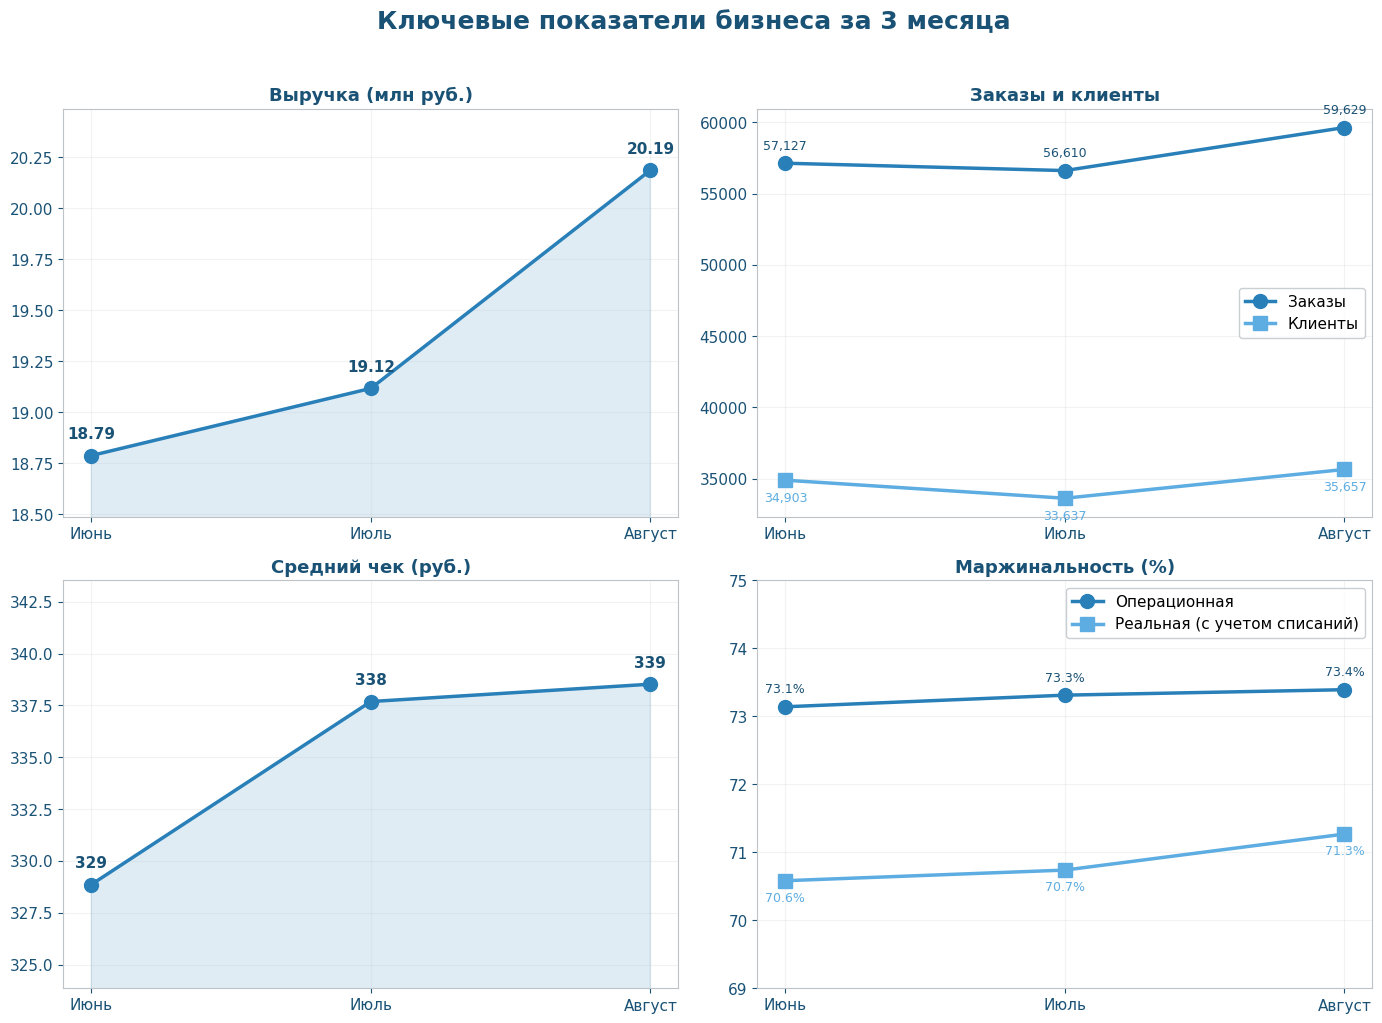

In [12]:
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelcolor'] = '#2C3E50'
plt.rcParams['axes.edgecolor'] = '#BDC3C7'
plt.rcParams['xtick.color'] = '#2C3E50'
plt.rcParams['ytick.color'] = '#2C3E50'

BLUE_PALETTE = {
    'main': '#1A5276',      # темно-синий
    'secondary': '#2980B9', # ярко-синий
    'light': '#5DADE2',     # светло-синий
    'lighter': '#85C1E9',   # очень светлый
    'accent': '#2ECC71',    # зеленый
    'accent2': '#F39C12',   # оранжевый
    'warm': '#E74C3C'       # красный 
    }
monthly_revenue = df_sales.groupby('Месяц')['Sales'].sum().reset_index()
monthly_revenue.columns = ['Месяц', 'Выручка']
monthly_revenue['Выручка_млн'] = monthly_revenue['Выручка'] / 1_000_000

monthly_orders = df_sales.groupby('Месяц')['NumberOfOrders'].sum().reset_index()
monthly_orders.columns = ['Месяц', 'Заказы']

monthly_customers = df_sales.groupby('Месяц')['NumberOfCustomers'].sum().reset_index()
monthly_customers.columns = ['Месяц', 'Клиенты']

monthly_avg_check = df_sales.groupby('Месяц').apply(
    lambda x: x['Sales'].sum() / x['NumberOfOrders'].sum()
).reset_index()
monthly_avg_check.columns = ['Месяц', 'Средний_чек']

monthly_margin = df_sales.groupby('Месяц').apply(
    lambda x: x['Profit'].sum() / x['Sales'].sum() * 100
).reset_index()
monthly_margin.columns = ['Месяц', 'Маржинальность_операционная']

material_cost = df_material.groupby('Месяц').agg({
    'Продано. Себестоимость': 'sum',
    'Выброшено. Себестоимость': 'sum'
}).reset_index()

sales_by_month = df_sales.groupby('Месяц')['Sales'].sum().reset_index()

margin_real = material_cost.merge(sales_by_month, on='Месяц')
margin_real['Маржинальность_реальная'] = (
    (margin_real['Sales'] - margin_real['Продано. Себестоимость'] - margin_real['Выброшено. Себестоимость']) 
    / margin_real['Sales'] * 100
)

metrics = monthly_revenue.merge(monthly_orders, on='Месяц')
metrics = metrics.merge(monthly_customers, on='Месяц')
metrics = metrics.merge(monthly_avg_check, on='Месяц')
metrics = metrics.merge(monthly_margin, on='Месяц')
metrics = metrics.merge(margin_real[['Месяц', 'Маржинальность_реальная']], on='Месяц')

metrics['Месяц_название'] = metrics['Месяц'].map(month_names)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Ключевые показатели бизнеса за 3 месяца', fontsize=18, fontweight='bold', y=1.02, color=BLUE_PALETTE['main'])

months = metrics['Месяц_название'].tolist()

# График 1: Выручка
ax1 = axes[0, 0]
ax1.plot(months, metrics['Выручка_млн'], marker='o', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['secondary'], label='Выручка')
ax1.fill_between(months, metrics['Выручка_млн'], alpha=0.15, color=BLUE_PALETTE['secondary'])
ax1.set_title('Выручка (млн руб.)', fontsize=13, fontweight='bold', color=BLUE_PALETTE['main'])
ax1.set_ylim(min(metrics['Выручка_млн']) - 0.3, max(metrics['Выручка_млн']) + 0.3)
ax1.grid(True, alpha=0.2, color='#BDC3C7')
ax1.tick_params(colors=BLUE_PALETTE['main'])
for spine in ax1.spines.values():
    spine.set_color('#BDC3C7')
for i, val in enumerate(metrics['Выручка_млн']):
    ax1.annotate(f'{val:.2f}', (months[i], val), textcoords="offset points", 
                xytext=(0, 12), ha='center', fontsize=11, fontweight='bold', color=BLUE_PALETTE['main'])

# График 2: Заказы и Клиенты
ax2 = axes[0, 1]
ax2.plot(months, metrics['Заказы'], marker='o', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['secondary'], label='Заказы')
ax2.plot(months, metrics['Клиенты'], marker='s', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['light'], label='Клиенты')
ax2.set_title('Заказы и клиенты', fontsize=13, fontweight='bold', color=BLUE_PALETTE['main'])
ax2.legend(loc='best', frameon=True, facecolor='white', edgecolor='#BDC3C7')
ax2.grid(True, alpha=0.2, color='#BDC3C7')
ax2.tick_params(colors=BLUE_PALETTE['main'])
for spine in ax2.spines.values():
    spine.set_color('#BDC3C7')
for i, (orders, clients) in enumerate(zip(metrics['Заказы'], metrics['Клиенты'])):
    ax2.annotate(f'{orders:,}', (months[i], orders), textcoords="offset points", 
                xytext=(0, 10), ha='center', fontsize=9, color=BLUE_PALETTE['main'])
    ax2.annotate(f'{clients:,}', (months[i], clients), textcoords="offset points", 
                xytext=(0, -15), ha='center', fontsize=9, color=BLUE_PALETTE['light'])

# График 3: Средний чек
ax3 = axes[1, 0]
ax3.plot(months, metrics['Средний_чек'], marker='o', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['secondary'])
ax3.fill_between(months, metrics['Средний_чек'], alpha=0.15, color=BLUE_PALETTE['secondary'])
ax3.set_title('Средний чек (руб.)', fontsize=13, fontweight='bold', color=BLUE_PALETTE['main'])
ax3.set_ylim(min(metrics['Средний_чек']) - 5, max(metrics['Средний_чек']) + 5)
ax3.grid(True, alpha=0.2, color='#BDC3C7')
ax3.tick_params(colors=BLUE_PALETTE['main'])
for spine in ax3.spines.values():
    spine.set_color('#BDC3C7')
for i, val in enumerate(metrics['Средний_чек']):
    ax3.annotate(f'{val:.0f}', (months[i], val), textcoords="offset points", 
                xytext=(0, 12), ha='center', fontsize=11, fontweight='bold', color=BLUE_PALETTE['main'])

# График 4: Маржинальность
ax4 = axes[1, 1]
ax4.plot(months, metrics['Маржинальность_операционная'], marker='o', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['secondary'], label='Операционная')
ax4.plot(months, metrics['Маржинальность_реальная'], marker='s', linewidth=2.5, markersize=10, 
         color=BLUE_PALETTE['light'], label='Реальная (с учетом списаний)')
ax4.set_title('Маржинальность (%)', fontsize=13, fontweight='bold', color=BLUE_PALETTE['main'])
ax4.legend(loc='best', frameon=True, facecolor='white', edgecolor='#BDC3C7')
ax4.set_ylim(69, 75)
ax4.grid(True, alpha=0.2, color='#BDC3C7')
ax4.tick_params(colors=BLUE_PALETTE['main'])
for spine in ax4.spines.values():
    spine.set_color('#BDC3C7')
for i, (op, real) in enumerate(zip(metrics['Маржинальность_операционная'], metrics['Маржинальность_реальная'])):
    ax4.annotate(f'{op:.1f}%', (months[i], op), textcoords="offset points", 
                xytext=(0, 10), ha='center', fontsize=9, color=BLUE_PALETTE['main'])
    ax4.annotate(f'{real:.1f}%', (months[i], real), textcoords="offset points", 
                xytext=(0, -15), ha='center', fontsize=9, color=BLUE_PALETTE['light'])

plt.tight_layout()
plt.show()

## Структура выручки

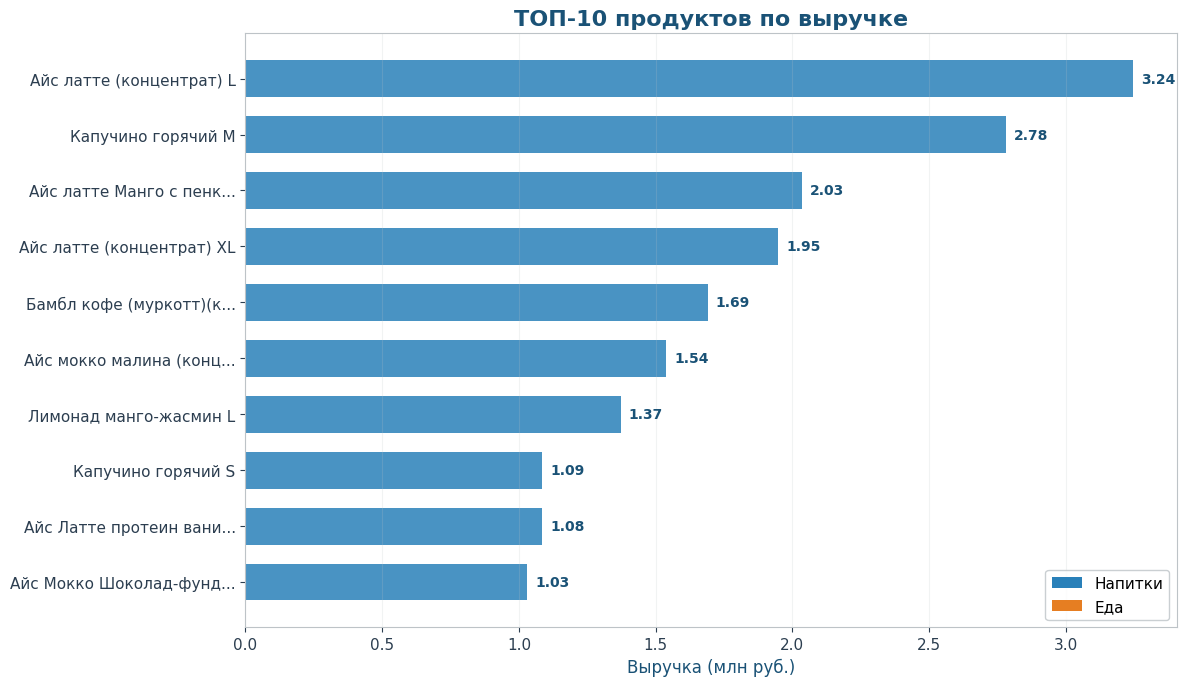

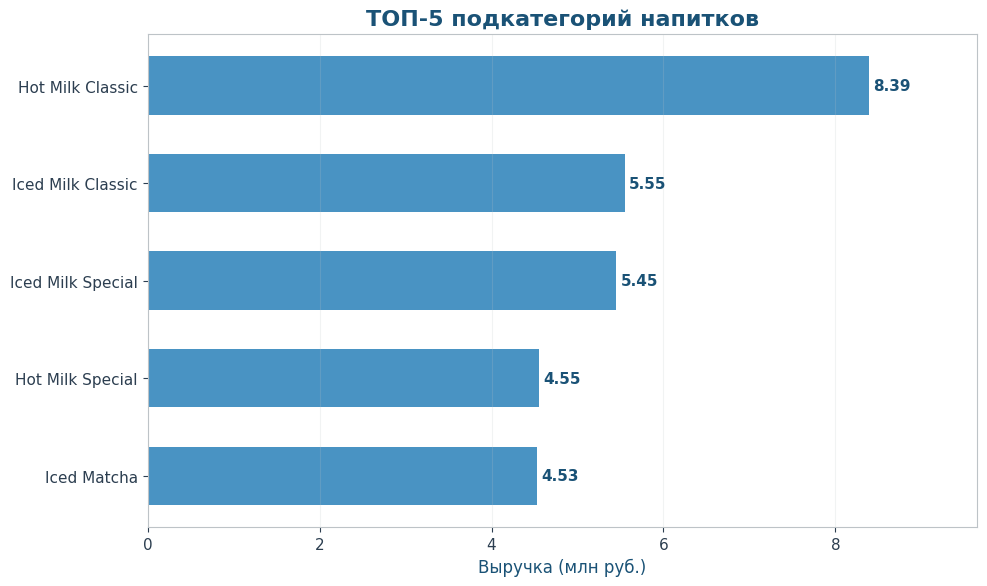

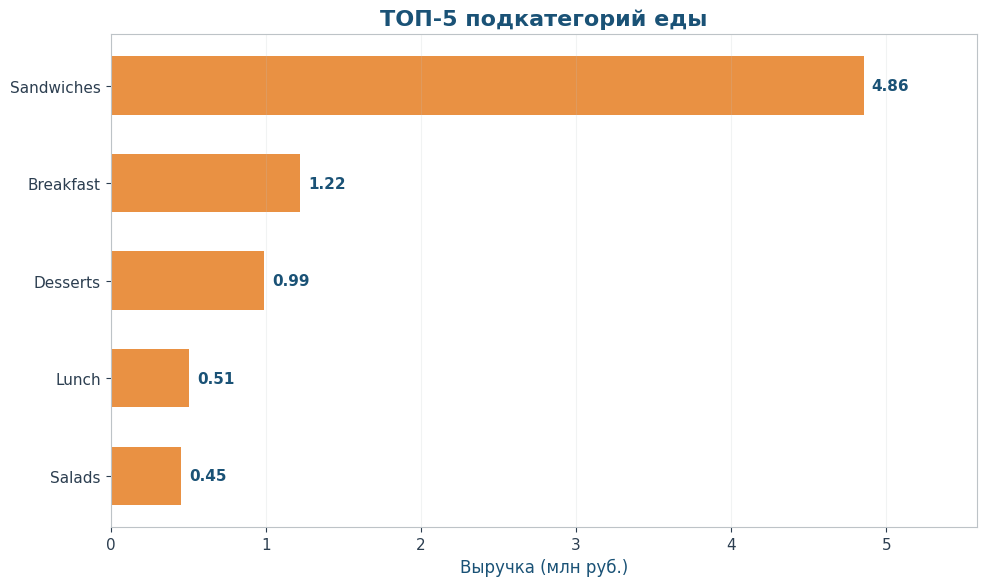

In [13]:
from matplotlib.patches import Patch
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11

BLUE_PALETTE = {
    'dark': '#1A5276',
    'main': '#2980B9',
    'light': '#5DADE2',
    'lighter': '#85C1E9',
    'warm': '#E67E22',
    'danger': '#E74C3C',
    'gray': '#95A5A6'
}

exclude_keywords = ['Стакан', 'Абонемент', 'Сертификат', 'Дрип-бокс', 'Кофе на продажу']
df_clean = df_sales[~df_sales['FullProductName'].str.contains('|'.join(exclude_keywords))]

#ТОП-10 продуктов по выручке
product_stats = df_clean.groupby(['FullProductName', 'CategoryName'])['Sales'].sum().reset_index()
product_stats['Sales_млн'] = product_stats['Sales'] / 1_000_000

top10 = product_stats.nlargest(10, 'Sales').copy()
top10 = top10.sort_values('Sales', ascending=True)

def shorten(name, max_len=25):
    if len(name) > max_len:
        return name[:max_len-3] + '...'
    return name

top10['ShortName'] = top10['FullProductName'].apply(lambda x: shorten(x, 25))

#ТОП-5 подкатегорий напитков
drinks = df_sales[df_sales['CategoryName'] == 'Напитки (Drinks)']
drinks_subcat = drinks.groupby('SubCategory')['Sales'].sum().reset_index()
drinks_subcat['Sales_млн'] = drinks_subcat['Sales'] / 1_000_000
drinks_subcat = drinks_subcat.nlargest(5, 'Sales')
drinks_subcat = drinks_subcat.sort_values('Sales', ascending=True)

#ТОП-5 подкатегорий еды
food = df_sales[df_sales['CategoryName'] == 'Еда (Food)']
food_subcat = food.groupby('SubCategory')['Sales'].sum().reset_index()
food_subcat['Sales_млн'] = food_subcat['Sales'] / 1_000_000
food_subcat = food_subcat.nlargest(5, 'Sales')
food_subcat = food_subcat.sort_values('Sales', ascending=True)

# ГРАФИК 1: ТОП-10 ПРОДУКТОВ ПО ВЫРУЧКЕ
fig, ax = plt.subplots(figsize=(12, 7))

colors = [BLUE_PALETTE['main'] if cat == 'Напитки (Drinks)' else BLUE_PALETTE['warm'] 
          for cat in top10['CategoryName']]

bars = ax.barh(top10['ShortName'], top10['Sales_млн'], color=colors, alpha=0.85, height=0.65)

ax.set_xlabel('Выручка (млн руб.)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-10 продуктов по выручке', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, color='#BDC3C7', axis='x')

for bar, row in zip(bars, top10.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height()/2,
            f'{row_data["Sales_млн"]:.2f}', 
            va='center', fontsize=10, fontweight='bold', color=BLUE_PALETTE['dark'])

legend_elements = [
    Patch(facecolor=BLUE_PALETTE['main'], label='Напитки'),
    Patch(facecolor=BLUE_PALETTE['warm'], label='Еда')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, 
          facecolor='white', edgecolor='#BDC3C7')

plt.tight_layout()
plt.show()

# ГРАФИК 2: ТОП-5 ПОДКАТЕГОРИЙ НАПИТКОВ
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(drinks_subcat['SubCategory'], drinks_subcat['Sales_млн'], 
               color=BLUE_PALETTE['main'], alpha=0.85, height=0.6)

ax.set_xlabel('Выручка (млн руб.)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-5 подкатегорий напитков', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, color='#BDC3C7', axis='x')

for bar, row in zip(bars, drinks_subcat.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f'{row_data["Sales_млн"]:.2f}', 
            va='center', fontsize=11, fontweight='bold', color=BLUE_PALETTE['dark'])

ax.set_xlim(0, drinks_subcat['Sales_млн'].max() * 1.15)

plt.tight_layout()
plt.show()

# ГРАФИК 3: ТОП-5 ПОДКАТЕГОРИЙ ЕДЫ
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(food_subcat['SubCategory'], food_subcat['Sales_млн'], 
               color=BLUE_PALETTE['warm'], alpha=0.85, height=0.6)

ax.set_xlabel('Выручка (млн руб.)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-5 подкатегорий еды', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, color='#BDC3C7', axis='x')

for bar, row in zip(bars, food_subcat.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f'{row_data["Sales_млн"]:.2f}', 
            va='center', fontsize=11, fontweight='bold', color=BLUE_PALETTE['dark'])

ax.set_xlim(0, food_subcat['Sales_млн'].max() * 1.15)
plt.tight_layout()
plt.show()

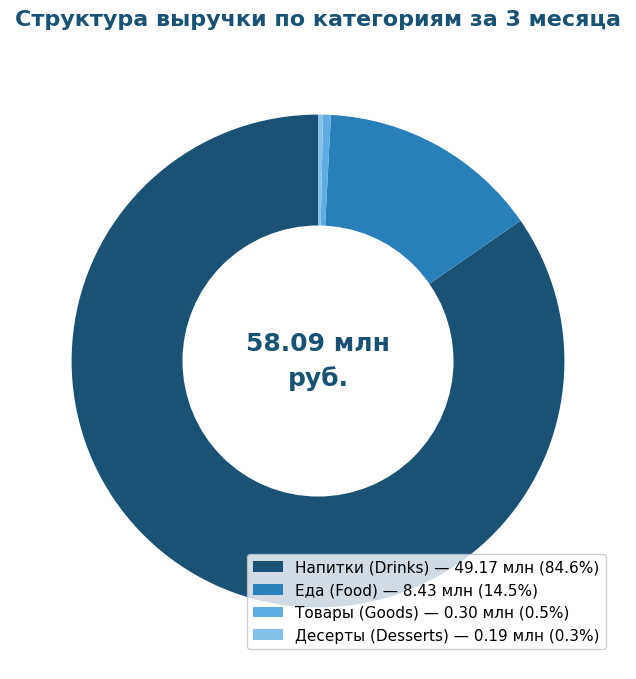

In [14]:
category_sales = df_sales.groupby('CategoryName')['Sales'].sum().reset_index()
category_sales.columns = ['CategoryName', 'TotalSales']
category_sales = category_sales.sort_values('TotalSales', ascending=False)
total_revenue = category_sales['TotalSales'].sum()
category_sales['Share'] = (category_sales['TotalSales'] / total_revenue * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 8))

colors = ['#1A5276', '#2980B9', '#5DADE2', '#85C1E9']

wedges, texts = ax.pie(
    category_sales['TotalSales'],
    colors=colors,
    startangle=90,
    textprops={'fontsize': 14, 'fontweight': 'bold', 'color': '#1A5276'},
    labeldistance=1.05,
)

# Центр
centre_circle = plt.Circle((0, 0), 0.55, fc='white', linewidth=0)
fig.gca().add_artist(centre_circle)

# Текст в центре
ax.text(0, 0, f'{total_revenue/1e6:.2f} млн\nруб.', 
        ha='center', va='center', fontsize=18, fontweight='bold', 
        color='#1A5276', linespacing=1.5)

legend_labels = []
for _, row in category_sales.iterrows():
    label = f'{row["CategoryName"]} — {row["TotalSales"]/1e6:.2f} млн ({row["Share"]:.1f}%)'
    legend_labels.append(label)

ax.legend(
    legend_labels, 
    loc='lower right',
    fontsize=11, 
    frameon=True, 
    facecolor='white',
    edgecolor='#BDC3C7',
    bbox_to_anchor=(0.98, 0.02)
)

ax.set_title('Структура выручки по категориям за 3 месяца', 
             fontsize=16, fontweight='bold', color='#1A5276', pad=20)

plt.show()

## Маржинальность

In [15]:
exclude_keywords = ['Стакан', 'Абонемент', 'Сертификат', 'Дрип-бокс', 'Кофе на продажу']
df_clean = df_sales[~df_sales['FullProductName'].str.contains('|'.join(exclude_keywords))]

print("ТОП-10 ПРОДУКТОВ ПО ВЫРУЧКЕ:")
top_sales = df_clean.groupby('FullProductName').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'NumberOfOrders': 'sum',
    'CategoryName': 'first'
}).reset_index()
top_sales['Маржинальность'] = (top_sales['Profit'] / top_sales['Sales'] * 100).round(2)
top_sales = top_sales.nlargest(10, 'Sales')
top_sales['Sales_млн'] = top_sales['Sales'] / 1000000
print(top_sales[['FullProductName', 'CategoryName', 'Sales_млн', 'Маржинальность', 'NumberOfOrders']].to_string(index=False))

print("\nТОП-10 ПО МАРЖИНАЛЬНОСТИ (продукты с продажами > 100 тыс. руб.):")
top_margin = df_clean.groupby('FullProductName').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'CategoryName': 'first'
}).reset_index()
top_margin['Маржинальность'] = (top_margin['Profit'] / top_margin['Sales'] * 100).round(2)
top_margin = top_margin[top_margin['Sales'] > 100000]
top_margin = top_margin.nlargest(10, 'Маржинальность')
top_margin['Sales_тыс'] = top_margin['Sales'] / 1000
print(top_margin[['FullProductName', 'CategoryName', 'Sales_тыс', 'Маржинальность']].to_string(index=False))

print("\nТОП-10 ПО НИЗКОЙ МАРЖИНАЛЬНОСТИ (продукты с продажами > 50 тыс. руб.):")
low_margin = df_clean.groupby('FullProductName').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'CategoryName': 'first'
}).reset_index()
low_margin['Маржинальность'] = (low_margin['Profit'] / low_margin['Sales'] * 100).round(2)
low_margin = low_margin[low_margin['Sales'] > 50000]
low_margin = low_margin.nsmallest(10, 'Маржинальность')
low_margin['Sales_тыс'] = low_margin['Sales'] / 1000
print(low_margin[['FullProductName', 'CategoryName', 'Sales_тыс', 'Маржинальность']].to_string(index=False))

ТОП-10 ПРОДУКТОВ ПО ВЫРУЧКЕ:
                        FullProductName     CategoryName  Sales_млн  Маржинальность  NumberOfOrders
               Айс латте (концентрат) L Напитки (Drinks)   3.243680           79.75            8633
                     Капучино горячий M Напитки (Drinks)   2.779390           79.14            8389
Айс латте Манго с пенкой (концентрат) L Напитки (Drinks)   2.034100           73.26            5104
              Айс латте (концентрат) XL Напитки (Drinks)   1.946669           76.68            4473
     Бамбл кофе (муркотт)(концентрат) L Напитки (Drinks)   1.689730           57.95            3880
        Айс мокко малина (концентрат) L Напитки (Drinks)   1.537301           74.21            4245
                 Лимонад манго-жасмин L Напитки (Drinks)   1.371509           70.63            3917
                     Капучино горячий S Напитки (Drinks)   1.085116           82.92            4190
Айс Латте протеин ваниль (концентрат) L Напитки (Drinks)   1.083977    

KeyError: 'Sales_млн'

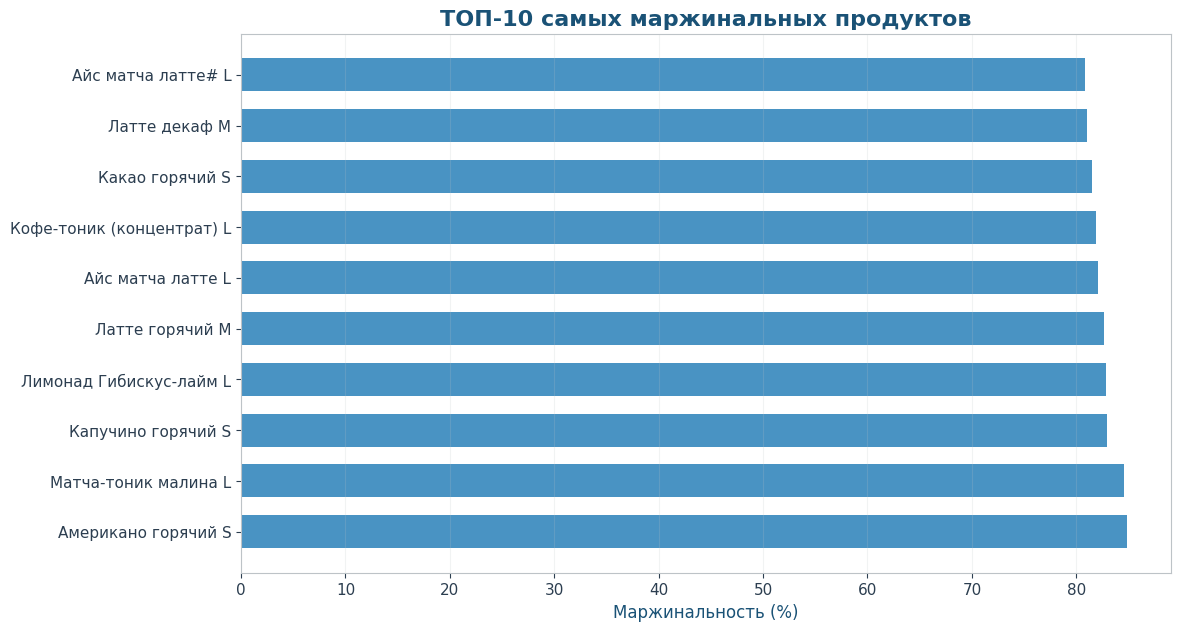

In [17]:
# Расчет маржинальности по продуктам
product_margin = df_clean.groupby(['FullProductName', 'CategoryName']).agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()
product_margin['Маржинальность'] = (product_margin['Profit'] / product_margin['Sales'] * 100).round(1)
product_margin['Sales_млн'] = product_margin['Sales'] / 1_000_000

def shorten(name, max_len=30):
    if len(name) > max_len:
        return name[:max_len-3] + '...'
    return name

top_margin['ShortName'] = top_margin['FullProductName'].apply(lambda x: shorten(x, 30))

fig, ax = plt.subplots(figsize=(12, 7))

colors = [BLUE_PALETTE['main'] if cat == 'Напитки (Drinks)' else BLUE_PALETTE['warm'] 
          for cat in top_margin['CategoryName']]

bars = ax.barh(top_margin['ShortName'], top_margin['Маржинальность'], 
               color=colors, alpha=0.85, height=0.65)

ax.set_xlabel('Маржинальность (%)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-10 самых маржинальных продуктов', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, color='#BDC3C7', axis='x')

# выручка
for bar, row in zip(bars, top_margin.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row_data["Sales_млн"]:.2f} млн', 
            va='center', fontsize=10, fontweight='bold', color=BLUE_PALETTE['dark'])

# Легенда
legend_elements = [
    Patch(facecolor=BLUE_PALETTE['main'], label='Напитки'),
    Patch(facecolor=BLUE_PALETTE['warm'], label='Еда')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, 
          facecolor='white', edgecolor='#BDC3C7')

plt.show()

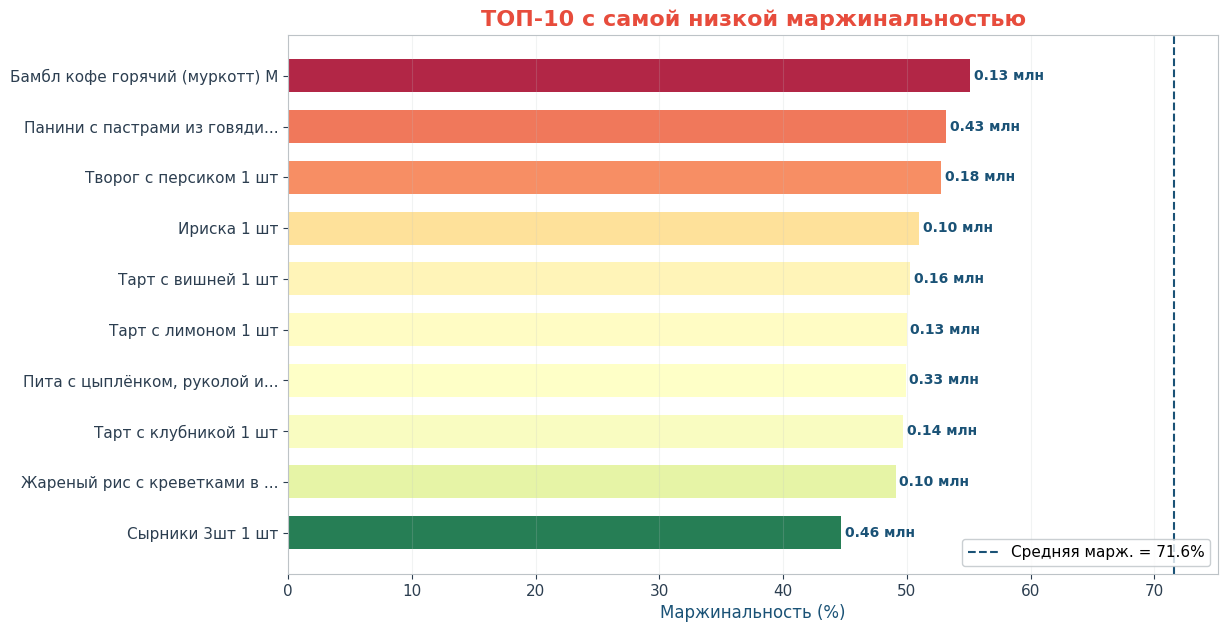

In [18]:
low_margin = product_margin[product_margin['Sales'] > 100000].nsmallest(10, 'Маржинальность').copy()
low_margin = low_margin.sort_values('Маржинальность', ascending=True)

low_margin['ShortName'] = low_margin['FullProductName'].apply(lambda x: shorten(x, 30))

fig, ax = plt.subplots(figsize=(12, 7))

margin_values = low_margin['Маржинальность'].values
norm_margin = (margin_values - margin_values.min()) / (margin_values.max() - margin_values.min())
colors = plt.cm.RdYlGn_r(norm_margin)  

bars = ax.barh(low_margin['ShortName'], low_margin['Маржинальность'], 
               color=colors, alpha=0.85, height=0.65)

ax.set_xlabel('Маржинальность (%)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-10 с самой низкой маржинальностью', fontsize=16, fontweight='bold', color=BLUE_PALETTE['danger'])
ax.grid(True, alpha=0.2, color='#BDC3C7', axis='x')

# выручка
for bar, row in zip(bars, low_margin.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row_data["Sales_млн"]:.2f} млн', 
            va='center', fontsize=10, fontweight='bold', color=BLUE_PALETTE['dark'])

# Красная линия — средняя маржинальность по бизнесу
avg_margin = product_margin[product_margin['Sales'] > 100000]['Маржинальность'].mean()
ax.axvline(x=avg_margin, color=BLUE_PALETTE['dark'], linestyle='--', linewidth=1.5, 
           label=f'Средняя марж. = {avg_margin:.1f}%')
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#BDC3C7')

plt.show()

In [19]:
drinks = df_clean[df_clean['CategoryName'] == 'Напитки (Drinks)']
drinks_subcat = drinks.groupby('SubCategory').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

drinks_subcat['Маржинальность'] = (drinks_subcat['Profit'] / drinks_subcat['Sales'] * 100).round(1)
drinks_subcat['Sales_млн'] = (drinks_subcat['Sales'] / 1_000_000).round(2)
drinks_subcat = drinks_subcat.sort_values('Маржинальность', ascending=False)

print("="*60)
print("НАПИТКИ: МАРЖИНАЛЬНОСТЬ ПО ПОДКАТЕГОРИЯМ")
print("="*60)
print(drinks_subcat[['SubCategory', 'Маржинальность', 'Sales_млн']].to_string(index=False))

avg_drinks_margin = drinks_subcat['Маржинальность'].mean()
print(f"\nСРЕДНЯЯ МАРЖИНАЛЬНОСТЬ НАПИТКОВ: {avg_drinks_margin:.1f}%")

food = df_clean[df_clean['CategoryName'] == 'Еда (Food)']
food_subcat = food.groupby('SubCategory').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

food_subcat['Маржинальность'] = (food_subcat['Profit'] / food_subcat['Sales'] * 100).round(1)
food_subcat['Sales_млн'] = (food_subcat['Sales'] / 1_000_000).round(2)
food_subcat = food_subcat.sort_values('Маржинальность', ascending=False)

print("\n" + "="*60)
print("ЕДА: МАРЖИНАЛЬНОСТЬ ПО ПОДКАТЕГОРИЯМ")
print("="*60)
print(food_subcat[['SubCategory', 'Маржинальность', 'Sales_млн']].to_string(index=False))

avg_food_margin = food_subcat['Маржинальность'].mean()
print(f"\nСРЕДНЯЯ МАРЖИНАЛЬНОСТЬ ЕДЫ: {avg_food_margin:.1f}%")

НАПИТКИ: МАРЖИНАЛЬНОСТЬ ПО ПОДКАТЕГОРИЯМ
        SubCategory  Маржинальность  Sales_млн
  Hot Mocha Special            82.1       0.00
            Hot Tea            80.7       0.41
         Iced Cocoa            79.8       1.02
   Hot Milk Classic            78.9       8.39
  Iced Milk Classic            78.5       5.55
          Hot Cocoa            78.3       1.07
 Hot Matcha Special            77.7       0.04
          Hot Black            77.1       1.92
         Hot Matcha            76.6       1.07
          Hot Mocha            75.2       0.78
        Iced Matcha            75.2       4.53
         Refreshers            75.1       4.11
   Hot Milk Special            74.9       4.55
         Iced Mocha            73.9       3.81
        Hot Non tea            73.7       0.22
  Iced Milk Special            73.1       5.45
         Iced Black            71.0       4.49
       Iced Non tea            70.9       0.46
           Iced Tea            69.9       0.86
Hot Hojicha Special

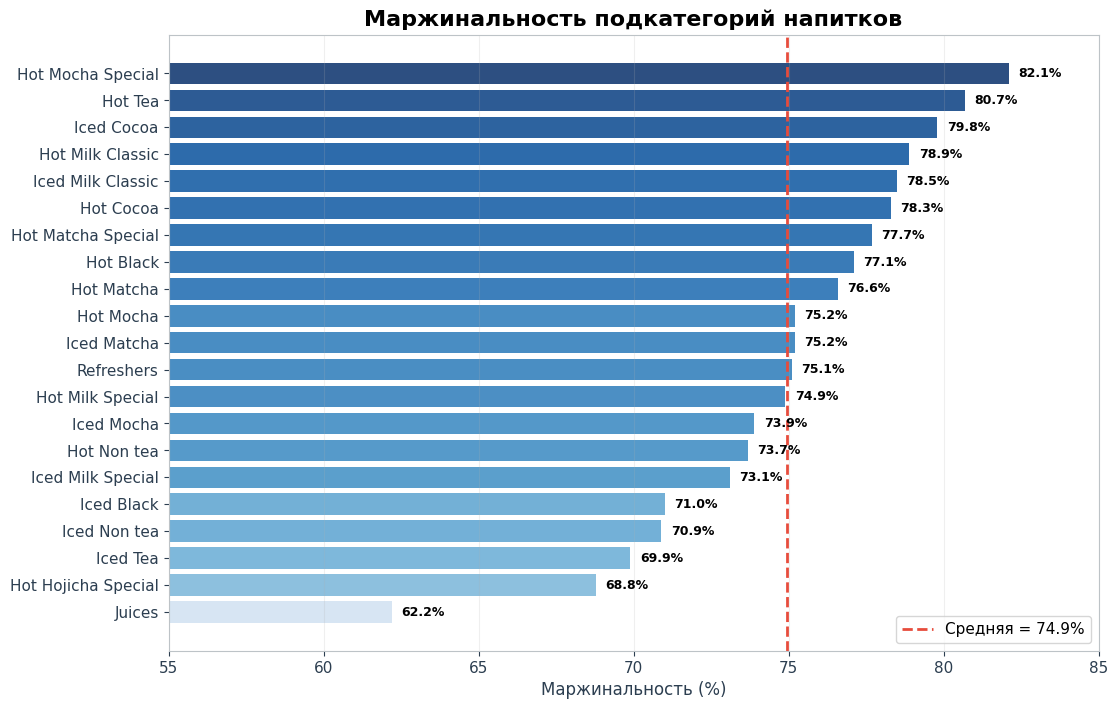

In [20]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_data = drinks_subcat.sort_values('Маржинальность', ascending=True)

norm = (plot_data['Маржинальность'] - plot_data['Маржинальность'].min()) / (plot_data['Маржинальность'].max() - plot_data['Маржинальность'].min())
colors = plt.cm.Blues(norm * 0.8 + 0.2)

bars = ax.barh(plot_data['SubCategory'], plot_data['Маржинальность'], color=colors, alpha=0.85)

ax.axvline(x=avg_drinks_margin, color='#E74C3C', linestyle='--', linewidth=2, label=f'Средняя = {avg_drinks_margin:.1f}%')

ax.set_xlabel('Маржинальность (%)', fontsize=12)
ax.set_title('Маржинальность подкатегорий напитков', fontsize=16, fontweight='bold')
ax.set_xlim(55, 85)
ax.grid(True, alpha=0.2, axis='x')
ax.legend(loc='lower right')

for bar, row in zip(bars, plot_data.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row_data["Маржинальность"]:.1f}%', va='center', fontsize=9, fontweight='bold')
plt.show()

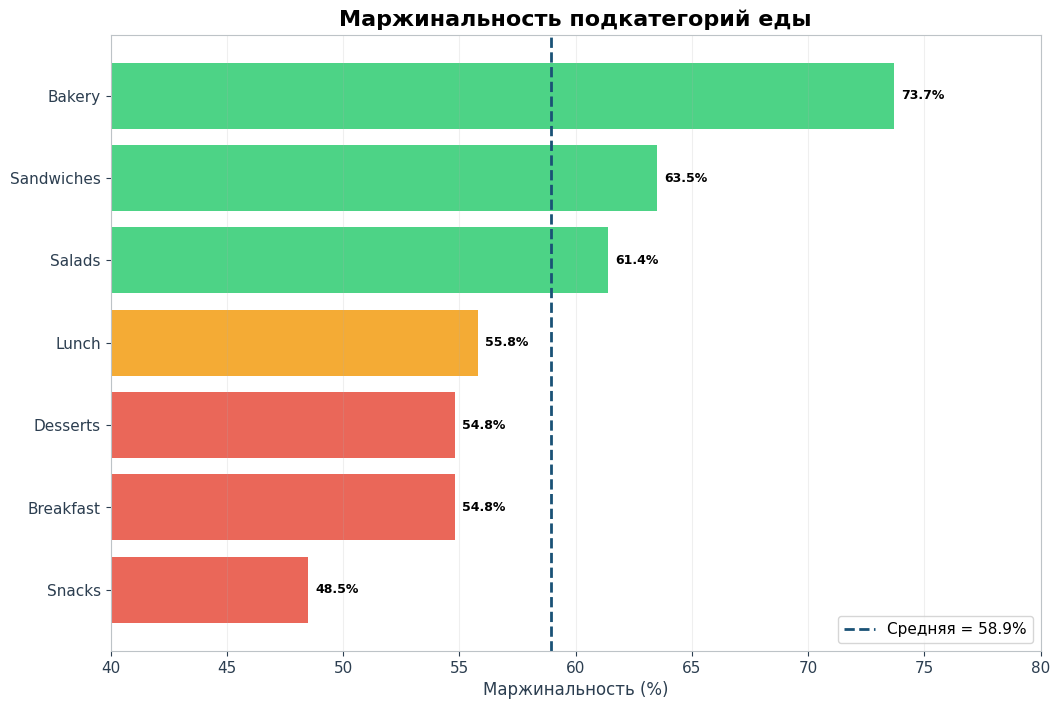

In [21]:
fig, ax = plt.subplots(figsize=(12, 8))
plot_data = food_subcat.sort_values('Маржинальность', ascending=True)
colors = ['#E74C3C' if m < 55 else '#F39C12' if m < 60 else '#2ECC71' for m in plot_data['Маржинальность']]

bars = ax.barh(plot_data['SubCategory'], plot_data['Маржинальность'], color=colors, alpha=0.85)

ax.axvline(x=avg_food_margin, color='#1A5276', linestyle='--', linewidth=2, label=f'Средняя = {avg_food_margin:.1f}%')

ax.set_xlabel('Маржинальность (%)', fontsize=12)
ax.set_title('Маржинальность подкатегорий еды', fontsize=16, fontweight='bold')
ax.set_xlim(40, 80)
ax.grid(True, alpha=0.2, axis='x')
ax.legend(loc='lower right')

for bar, row in zip(bars, plot_data.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row_data["Маржинальность"]:.1f}%', va='center', fontsize=9, fontweight='bold')
plt.show()

## Анализ себестоимости и списаний

In [22]:
print("ТОП-10 ИНГРЕДИЕНТОВ ПО ОБЩЕЙ СЕБЕСТОИМОСТИ:")
top_cost = df_material.groupby('MaterialName').agg({
    'Продано. Себестоимость': 'sum',
    'Выброшено. Себестоимость': 'sum'
}).reset_index()
top_cost['Общая_себестоимость'] = top_cost['Продано. Себестоимость'] + top_cost['Выброшено. Себестоимость']
top_cost['Доля_списаний'] = (top_cost['Выброшено. Себестоимость'] / top_cost['Общая_себестоимость'] * 100).round(2)
top_cost = top_cost.nlargest(10, 'Общая_себестоимость')
top_cost['Общая_себестоимость_тыс'] = top_cost['Общая_себестоимость'] / 1000
print(top_cost[['MaterialName', 'Общая_себестоимость_тыс', 'Доля_списаний']].to_string(index=False))

ТОП-10 ИНГРЕДИЕНТОВ ПО ОБЩЕЙ СЕБЕСТОИМОСТИ:
                       MaterialName  Общая_себестоимость_тыс  Доля_списаний
                    Концентрат кофе              1390.505061           1.43
                Молоко коровье 3,2%              1309.620766           2.34
                Кофе зерно эспрессо              1175.640013          10.46
        Сок апельсиновый Муркотовый               943.961146           6.33
                   Молоко кокосовое               664.531049           1.77
                       Сырная пенка               616.907837          19.89
                        Манго пенка               508.821074          20.65
Стакан для ХОЛОДНЫХ напитков 400 мл               463.479820           1.55
                Сироп Кордиал манго               428.762191           1.60
                  Ванильный протеин               308.346090           1.27


In [23]:
monthly_waste = df_material.groupby('Месяц').agg({
    'Продано. Себестоимость': 'sum',
    'Выброшено. Себестоимость': 'sum'
}).reset_index()
monthly_waste['Общая_себестоимость'] = monthly_waste['Продано. Себестоимость'] + monthly_waste['Выброшено. Себестоимость']
monthly_waste['Доля_списаний'] = (monthly_waste['Выброшено. Себестоимость'] / monthly_waste['Общая_себестоимость'] * 100).round(2)
monthly_waste['Месяц_название'] = monthly_waste['Месяц'].map(month_names)
monthly_waste['Выброшено_тыс'] = monthly_waste['Выброшено. Себестоимость'] / 1000

print("ДИНАМИКА СПИСАНИЙ ПО МЕСЯЦАМ:")
print(monthly_waste[['Месяц_название', 'Выброшено_тыс', 'Доля_списаний']].to_string(index=False))

total_waste = df_material['Выброшено. Себестоимость'].sum()
total_cost = df_material['Продано. Себестоимость'].sum()
total_waste_pct = total_waste / (total_cost + total_waste) * 100

print(f"\nИТОГО ЗА 3 МЕСЯЦА:")
print(f"  Списания: {total_waste/1000:.0f} тыс. руб.")
print(f"  Доля списаний: {total_waste_pct:.2f}%")

waste_by_category = df_material.groupby('MaterialCategory').agg({
    'Выброшено. Себестоимость': 'sum',
    'Продано. Себестоимость': 'sum'
}).reset_index()
waste_by_category['Общая_себестоимость'] = waste_by_category['Продано. Себестоимость'] + waste_by_category['Выброшено. Себестоимость']
waste_by_category['Доля_списаний'] = (waste_by_category['Выброшено. Себестоимость'] / waste_by_category['Общая_себестоимость'] * 100).round(2)
waste_by_category = waste_by_category.sort_values('Доля_списаний', ascending=False)
waste_by_category['Выброшено_тыс'] = waste_by_category['Выброшено. Себестоимость'] / 1000

print("\nСПИСАНИЯ ПО КАТЕГОРИЯМ МАТЕРИАЛОВ:")
print(waste_by_category[['MaterialCategory', 'Выброшено_тыс', 'Доля_списаний']].to_string(index=False))

top_waste = df_material.groupby('MaterialName').agg({
    'Выброшено. Себестоимость': 'sum',
    'Продано. Себестоимость': 'sum'
}).reset_index()
top_waste['Общая_себестоимость'] = top_waste['Продано. Себестоимость'] + top_waste['Выброшено. Себестоимость']
top_waste['Доля_списаний'] = (top_waste['Выброшено. Себестоимость'] / top_waste['Общая_себестоимость'] * 100).round(2)
top_waste = top_waste[top_waste['Общая_себестоимость'] > 50000]
top_waste = top_waste.nlargest(10, 'Выброшено. Себестоимость')
top_waste['Выброшено_тыс'] = top_waste['Выброшено. Себестоимость'] / 1000

print("\nТОП-10 ИНГРЕДИЕНТОВ ПО СПИСАНИЯМ:")
print(top_waste[['MaterialName', 'Выброшено_тыс', 'Доля_списаний']].to_string(index=False))

top_waste_pct = df_material.groupby('MaterialName').agg({
    'Выброшено. Себестоимость': 'sum',
    'Продано. Себестоимость': 'sum'
}).reset_index()
top_waste_pct['Общая_себестоимость'] = top_waste_pct['Продано. Себестоимость'] + top_waste_pct['Выброшено. Себестоимость']
top_waste_pct = top_waste_pct[top_waste_pct['Общая_себестоимость'] > 50000]
top_waste_pct['Доля_списаний'] = (top_waste_pct['Выброшено. Себестоимость'] / top_waste_pct['Общая_себестоимость'] * 100).round(2)
top_waste_pct = top_waste_pct.nlargest(10, 'Доля_списаний')
top_waste_pct['Выброшено_тыс'] = top_waste_pct['Выброшено. Себестоимость'] / 1000

print("\nТОП-10 ПО ДОЛЕ СПИСАНИЙ (значимые ингредиенты):")
print(top_waste_pct[['MaterialName', 'Выброшено_тыс', 'Доля_списаний']].to_string(index=False))

# Операционная маржинальность
monthly_margin = df_sales.groupby('Месяц').apply(
    lambda x: x['Profit'].sum() / x['Sales'].sum() * 100
).reset_index()
monthly_margin.columns = ['Месяц', 'Маржинальность_операционная']

# Продажи по месяцам
sales_by_month = df_sales.groupby('Месяц')['Sales'].sum().reset_index()

# Реальная маржинальность
real_margin = monthly_waste.merge(sales_by_month, on='Месяц')
real_margin['Маржинальность_реальная'] = (
    (real_margin['Sales'] - real_margin['Продано. Себестоимость'] - real_margin['Выброшено. Себестоимость']) 
    / real_margin['Sales'] * 100
).round(2)

margin_comparison = monthly_margin.merge(real_margin[['Месяц', 'Маржинальность_реальная']], on='Месяц')
margin_comparison['Разница_пп'] = (margin_comparison['Маржинальность_операционная'] - margin_comparison['Маржинальность_реальная']).round(2)
margin_comparison['Месяц_название'] = margin_comparison['Месяц'].map(month_names)

print("\nВЛИЯНИЕ СПИСАНИЙ НА МАРЖИНАЛЬНОСТЬ:")
print(margin_comparison[['Месяц_название', 'Маржинальность_операционная', 'Маржинальность_реальная', 'Разница_пп']].to_string(index=False))

# Итого
avg_margin_op = margin_comparison['Маржинальность_операционная'].mean()
avg_margin_real = margin_comparison['Маржинальность_реальная'].mean()
avg_diff = margin_comparison['Разница_пп'].mean()

print(f"\nСРЕДНИЕ ЗА 3 МЕСЯЦА:")
print(f"  Операционная маржинальность: {avg_margin_op:.1f}%")
print(f"  Реальная маржинальность:     {avg_margin_real:.1f}%")
print(f"  Потери от списаний:          {avg_diff:.2f} п.п.")

# Потери в деньгах
total_sales = df_sales['Sales'].sum()
waste_loss_pct = total_waste / total_sales * 100
print(f"\nПОТЕРИ ОТ СПИСАНИЙ В ДЕНЬГАХ:")
print(f"  За 3 месяца: {total_waste/1000:.0f} тыс. руб.")
print(f"  Доля от выручки: {waste_loss_pct:.2f}%")

ДИНАМИКА СПИСАНИЙ ПО МЕСЯЦАМ:
Месяц_название  Выброшено_тыс  Доля_списаний
          Июнь     478.939698           8.67
          Июль     491.877111           8.79
        Август     448.582472           7.73

ИТОГО ЗА 3 МЕСЯЦА:
  Списания: 1419 тыс. руб.
  Доля списаний: 8.39%

СПИСАНИЯ ПО КАТЕГОРИЯМ МАТЕРИАЛОВ:
 MaterialCategory  Выброшено_тыс  Доля_списаний
Готовая продукция     673.030819          17.16
     Полуфабрикат     245.448737          15.08
       Ингредиент     479.480841           4.79
         Упаковка      21.438830           1.58
       Расходники       0.000053           0.59

ТОП-10 ИНГРЕДИЕНТОВ ПО СПИСАНИЯМ:
                 MaterialName  Выброшено_тыс  Доля_списаний
          Кофе зерно эспрессо     123.019403          10.46
                 Сырная пенка     122.693157          19.89
                  Манго пенка     105.066626          20.65
            Кофе зерно Руанда      63.150499          37.23
  Сок апельсиновый Муркотовый      59.798873           6.33
 

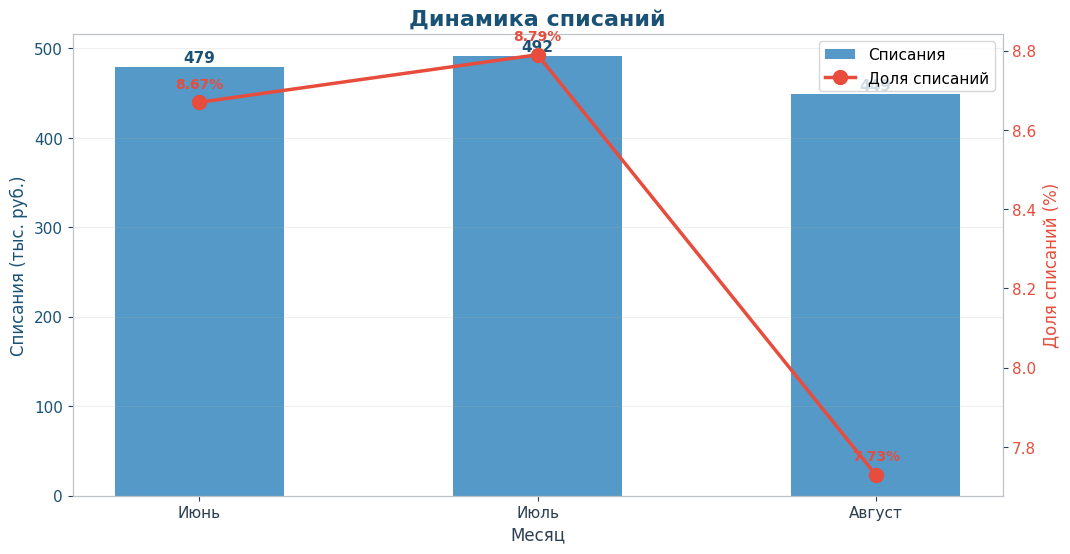

In [24]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Столбцы - списания
bars = ax1.bar(monthly_waste['Месяц_название'], monthly_waste['Выброшено_тыс'], 
               color=BLUE_PALETTE['main'], alpha=0.8, width=0.5, label='Списания')
ax1.set_xlabel('Месяц', fontsize=12)
ax1.set_ylabel('Списания (тыс. руб.)', fontsize=12, color=BLUE_PALETTE['dark'])
ax1.tick_params(axis='y', labelcolor=BLUE_PALETTE['dark'])

for bar, val in zip(bars, monthly_waste['Выброшено_тыс']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f'{val:.0f}', ha='center', fontsize=11, fontweight='bold', color=BLUE_PALETTE['dark'])

# Вторая ось - доля списаний
ax2 = ax1.twinx()
ax2.plot(monthly_waste['Месяц_название'], monthly_waste['Доля_списаний'], 
         marker='o', linewidth=2.5, markersize=10, color=BLUE_PALETTE['danger'], label='Доля списаний')
ax2.set_ylabel('Доля списаний (%)', fontsize=12, color=BLUE_PALETTE['danger'])
ax2.tick_params(axis='y', labelcolor=BLUE_PALETTE['danger'])

for i, val in enumerate(monthly_waste['Доля_списаний']):
    ax2.annotate(f'{val:.2f}%', (monthly_waste['Месяц_название'].iloc[i], val),
                 textcoords="offset points", xytext=(0, 10), ha='center',
                 fontsize=10, fontweight='bold', color=BLUE_PALETTE['danger'])

ax1.set_title('Динамика списаний', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax1.grid(True, alpha=0.2, axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
plt.show()

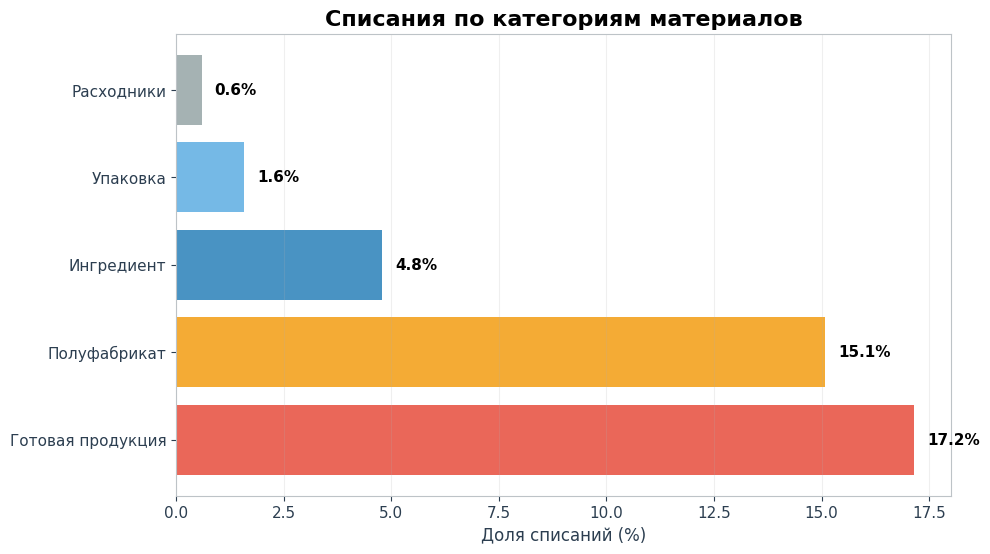

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#E74C3C', '#F39C12', '#2980B9', '#5DADE2', '#95A5A6']
bars = ax.barh(waste_by_category['MaterialCategory'], waste_by_category['Доля_списаний'], 
               color=colors, alpha=0.85)

ax.set_xlabel('Доля списаний (%)', fontsize=12)
ax.set_title('Списания по категориям материалов', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.2, axis='x')

for bar, row in zip(bars, waste_by_category.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row_data["Доля_списаний"]:.1f}%', va='center', fontsize=11, fontweight='bold')
plt.show()

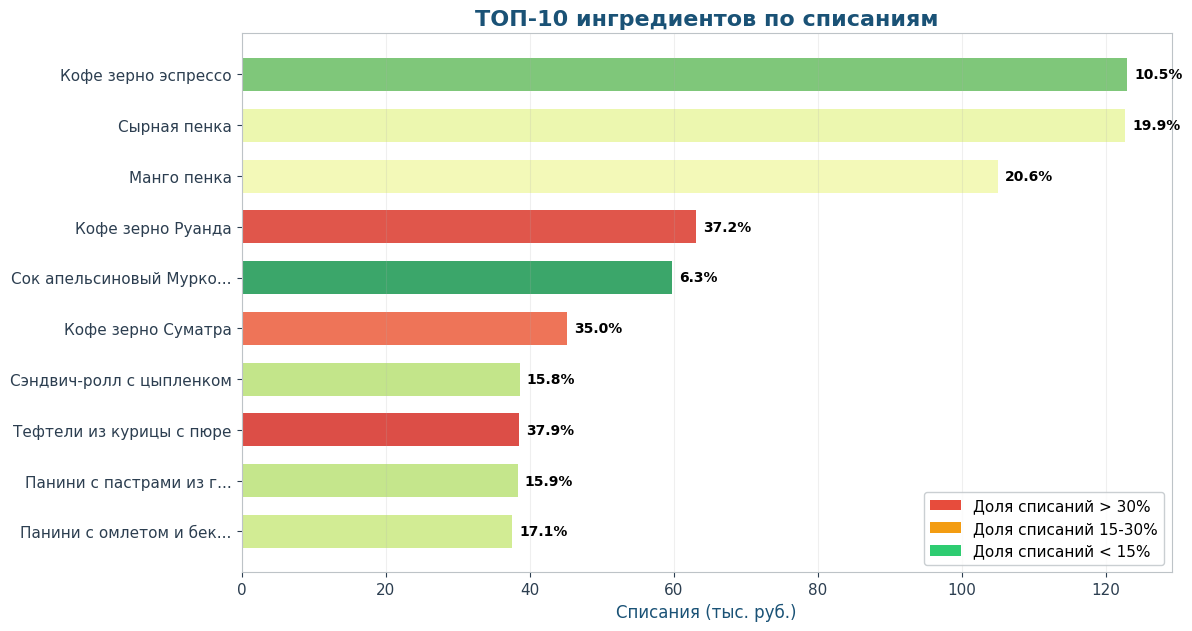

In [26]:
top_waste = df_material.groupby('MaterialName').agg({
    'Выброшено. Себестоимость': 'sum',
    'Продано. Себестоимость': 'sum'
}).reset_index()
top_waste['Общая_себестоимость'] = top_waste['Продано. Себестоимость'] + top_waste['Выброшено. Себестоимость']
top_waste['Доля_списаний'] = (top_waste['Выброшено. Себестоимость'] / top_waste['Общая_себестоимость'] * 100).round(2)
top_waste = top_waste[top_waste['Общая_себестоимость'] > 50000]
top_waste = top_waste.nlargest(10, 'Выброшено. Себестоимость')
top_waste['Выброшено_тыс'] = top_waste['Выброшено. Себестоимость'] / 1000
top_waste = top_waste.sort_values('Выброшено_тыс', ascending=True)

def shorten(name, max_len=25):
    if len(name) > max_len:
        return name[:max_len-3] + '...'
    return name

top_waste['ShortName'] = top_waste['MaterialName'].apply(lambda x: shorten(x, 25))

fig, ax = plt.subplots(figsize=(12, 7))
norm = (top_waste['Доля_списаний'] - top_waste['Доля_списаний'].min()) / (top_waste['Доля_списаний'].max() - top_waste['Доля_списаний'].min())
colors = plt.cm.RdYlGn_r(norm * 0.8 + 0.1)

bars = ax.barh(top_waste['ShortName'], top_waste['Выброшено_тыс'], color=colors, alpha=0.85, height=0.65)

ax.set_xlabel('Списания (тыс. руб.)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-10 ингредиентов по списаниям', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, axis='x')

# доля списаний
for bar, row in zip(bars, top_waste.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f'{row_data["Доля_списаний"]:.1f}%', va='center', fontsize=10, fontweight='bold')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='Доля списаний > 30%'),
    Patch(facecolor='#F39C12', label='Доля списаний 15-30%'),
    Patch(facecolor='#2ECC71', label='Доля списаний < 15%')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white', edgecolor='#BDC3C7')
plt.show()

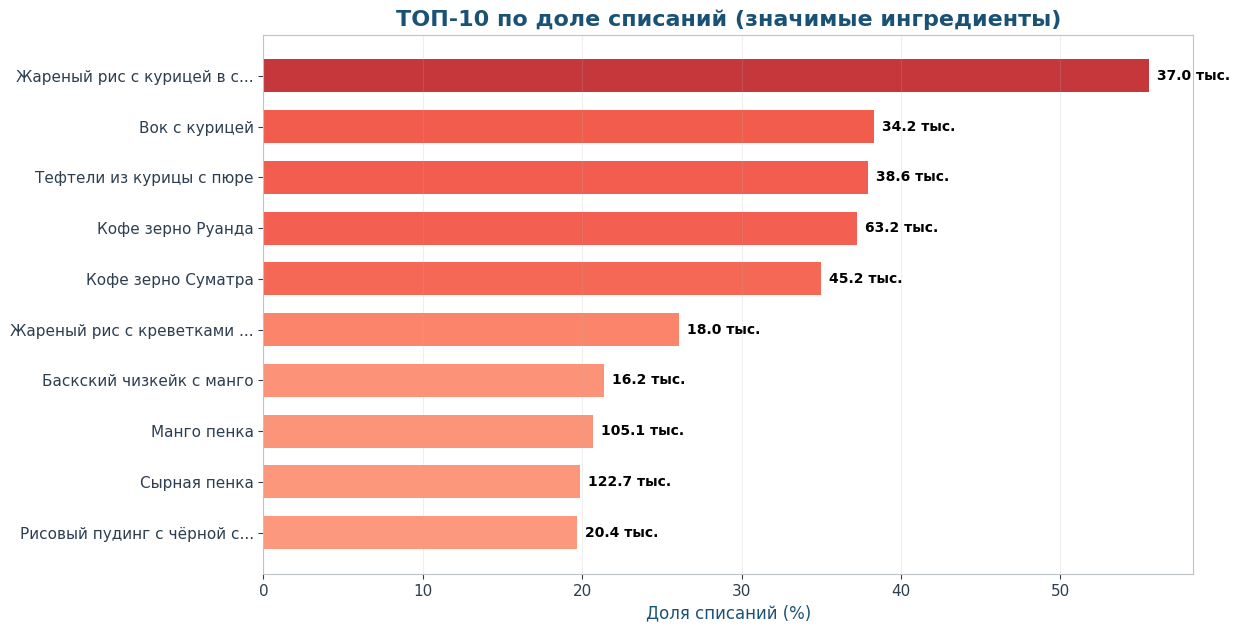

In [27]:
top_waste_pct = df_material.groupby('MaterialName').agg({
    'Выброшено. Себестоимость': 'sum',
    'Продано. Себестоимость': 'sum'
}).reset_index()
top_waste_pct['Общая_себестоимость'] = top_waste_pct['Продано. Себестоимость'] + top_waste_pct['Выброшено. Себестоимость']
top_waste_pct = top_waste_pct[top_waste_pct['Общая_себестоимость'] > 50000]
top_waste_pct['Доля_списаний'] = (top_waste_pct['Выброшено. Себестоимость'] / top_waste_pct['Общая_себестоимость'] * 100).round(2)
top_waste_pct = top_waste_pct.nlargest(10, 'Доля_списаний')
top_waste_pct['Выброшено_тыс'] = top_waste_pct['Выброшено. Себестоимость'] / 1000
top_waste_pct = top_waste_pct.sort_values('Доля_списаний', ascending=True)

def shorten(name, max_len=28):
    if len(name) > max_len:
        return name[:max_len-3] + '...'
    return name

top_waste_pct['ShortName'] = top_waste_pct['MaterialName'].apply(lambda x: shorten(x, 28))

fig, ax = plt.subplots(figsize=(12, 7))
norm = top_waste_pct['Доля_списаний'] / top_waste_pct['Доля_списаний'].max()
colors = plt.cm.Reds(norm * 0.6 + 0.2)

bars = ax.barh(top_waste_pct['ShortName'], top_waste_pct['Доля_списаний'], color=colors, alpha=0.85, height=0.65)

ax.set_xlabel('Доля списаний (%)', fontsize=12, color=BLUE_PALETTE['dark'])
ax.set_title('ТОП-10 по доле списаний (значимые ингредиенты)', fontsize=16, fontweight='bold', color=BLUE_PALETTE['dark'])
ax.grid(True, alpha=0.2, axis='x')

# суммы списаний
for bar, row in zip(bars, top_waste_pct.iterrows()):
    row_data = row[1]
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{row_data["Выброшено_тыс"]:.1f} тыс.', va='center', fontsize=10, fontweight='bold')
plt.show()